In [5]:
from google.colab import files

uploaded = files.upload()

Saving Dataset.csv to Dataset.csv


In [6]:
import pandas as pd
import io

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Loaded file:", filename)
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Loaded file: Dataset.csv
Dataset shape: (8790, 10)

Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [7]:
# Check missing values and duplicate rows
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing values in selected columns
df["director"] = df["director"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["rating"] = df["rating"].fillna("Unknown")
df["duration"] = df["duration"].fillna("Unknown")
df["listed_in"] = df["listed_in"].fillna("Unknown")

# Convert release year to numeric and fill missing years with the median
df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
df["release_year"] = df["release_year"].fillna(
    df["release_year"].median()
)

print("\nDataset shape after cleaning:", df.shape)
print("\nRemaining missing values:")
print(df.isnull().sum())

Missing values before cleaning:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate rows: 0

Dataset shape after cleaning: (8790, 10)

Remaining missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD

# Work on a copy
data = df.copy()

# Convert duration into a numerical value
data["duration_value"] = pd.to_numeric(
    data["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
).fillna(0)

# Encode categorical features
categorical_features = ["type", "rating", "country"]
encoder = OneHotEncoder(handle_unknown="ignore")

categorical_encoded = encoder.fit_transform(data[categorical_features])

# Scale numerical features
scaler = StandardScaler()
numeric_scaled = scaler.fit_transform(
    data[["release_year", "duration_value"]]
)

# Represent genres/categories as TF-IDF features
tfidf = TfidfVectorizer(max_features=300, stop_words="english")
genre_features = tfidf.fit_transform(data["listed_in"].astype(str))

# Combine features
from scipy.sparse import hstack, csr_matrix

X = hstack([
    categorical_encoded,
    csr_matrix(numeric_scaled),
    genre_features
]).tocsr()

print("Feature matrix shape:", X.shape)

Feature matrix shape: (8790, 148)


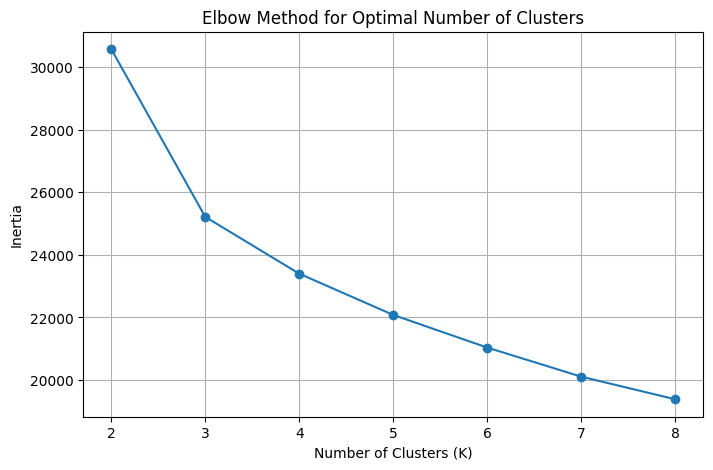

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertia_values = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [10]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

data["cluster"] = kmeans.fit_predict(X)

print("Clustering completed successfully!")
print("\nNumber of titles in each cluster:")
print(data["cluster"].value_counts().sort_index())

Clustering completed successfully!

Number of titles in each cluster:
cluster
0    3409
1    2164
2    2650
3     567
Name: count, dtype: int64


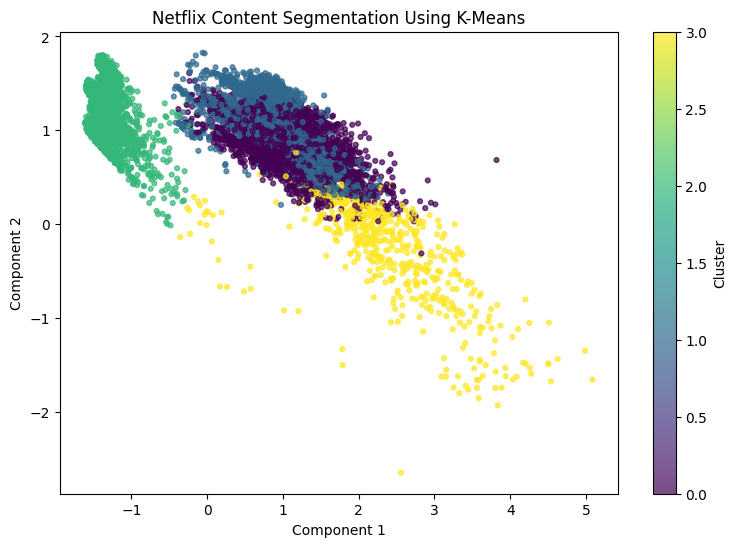

In [11]:
from sklearn.decomposition import TruncatedSVD

svd = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd.fit_transform(X)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=data["cluster"],
    cmap="viridis",
    s=12,
    alpha=0.7
)

plt.title("Netflix Content Segmentation Using K-Means")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [12]:
for cluster_id in sorted(data["cluster"].unique()):
    group = data[data["cluster"] == cluster_id]

    print(f"\n--- Cluster {cluster_id} ---")
    print("Number of titles:", len(group))

    print("\nContent types:")
    print(group["type"].value_counts().head(3))

    print("\nCommon genres/categories:")
    print(
        group["listed_in"]
        .str.split(", ")
        .explode()
        .value_counts()
        .head(5)
    )

    print("\nCommon ratings:")
    print(group["rating"].value_counts().head(3))


--- Cluster 0 ---
Number of titles: 3409

Content types:
type
Movie    3409
Name: count, dtype: int64

Common genres/categories:
listed_in
International Movies    2519
Dramas                  1609
Comedies                 963
Action & Adventure       446
Independent Movies       395
Name: count, dtype: int64

Common ratings:
rating
TV-MA    1360
TV-14    1075
TV-PG     332
Name: count, dtype: int64

--- Cluster 1 ---
Number of titles: 2164

Content types:
type
Movie    2164
Name: count, dtype: int64

Common genres/categories:
listed_in
Dramas                      569
Comedies                    531
Documentaries               450
Children & Family Movies    348
Independent Movies          319
Name: count, dtype: int64

Common ratings:
rating
TV-MA    642
R        436
PG-13    294
Name: count, dtype: int64

--- Cluster 2 ---
Number of titles: 2650

Content types:
type
TV Show    2637
Movie        13
Name: count, dtype: int64

Common genres/categories:
listed_in
International TV Shows  

In [13]:
cluster_summary = data.groupby("cluster").agg(
    total_titles=("title", "count"),
    average_release_year=("release_year", "mean"),
    unique_content_types=("type", "nunique"),
    unique_ratings=("rating", "nunique")
).round(2)

print("Netflix Content Segmentation Summary")
display(cluster_summary)

Netflix Content Segmentation Summary


,total_titles,average_release_year,unique_content_types,unique_ratings
cluster,,,,
0,3409,2015.81,1,14
1,2164,2015.21,1,14
2,2650,2017.01,2,9
3,567,1987.26,2,12


In [14]:
for cluster_id in sorted(data["cluster"].unique()):
    print(f"\nCluster {cluster_id} — Sample Titles")
    display(
        data.loc[
            data["cluster"] == cluster_id,
            ["title", "type", "release_year", "rating", "listed_in"]
        ].head(5)
    )


Cluster 0 — Sample Titles


,title,type,release_year,rating,listed_in
3,Confessions of an Invisible Girl,Movie,2021,TV-PG,"Children & Family Movies, Comedies"
7,Motu Patlu in the Game of Zones,Movie,2019,TV-Y7,"Children & Family Movies, Comedies, Music & Mu..."
8,Je Suis Karl,Movie,2021,TV-MA,"Dramas, International Movies"
9,Motu Patlu in Wonderland,Movie,2013,TV-Y7,"Children & Family Movies, Music & Musicals"
10,Motu Patlu: Deep Sea Adventure,Movie,2014,TV-Y7,"Children & Family Movies, Comedies"



Cluster 1 — Sample Titles


,title,type,release_year,rating,listed_in
0,Dick Johnson Is Dead,Movie,2020,PG-13,Documentaries
6,The Starling,Movie,2021,PG-13,"Comedies, Dramas"
13,Bridgerton - The Afterparty,Movie,2021,TV-14,Movies
14,Bling Empire - The Afterparty,Movie,2021,TV-MA,Movies
15,Cobra Kai - The Afterparty,Movie,2021,TV-MA,Movies



Cluster 2 — Sample Titles


,title,type,release_year,rating,listed_in
1,Ganglands,TV Show,2021,TV-MA,"Crime TV Shows, International TV Shows, TV Act..."
2,Midnight Mass,TV Show,2021,TV-MA,"TV Dramas, TV Horror, TV Mysteries"
5,The Great British Baking Show,TV Show,2021,TV-14,"British TV Shows, Reality TV"
17,Jailbirds New Orleans,TV Show,2021,TV-MA,"Docuseries, Reality TV"
18,Crime Stories: India Detectives,TV Show,2021,TV-MA,"British TV Shows, Crime TV Shows, Docuseries"



Cluster 3 — Sample Titles


,title,type,release_year,rating,listed_in
4,Sankofa,Movie,1993,TV-MA,"Dramas, Independent Movies, International Movies"
29,Jeans,Movie,1998,TV-14,"Comedies, International Movies, Romantic Movies"
51,Minsara Kanavu,Movie,1997,TV-PG,"Comedies, International Movies, Music & Musicals"
53,Avvai Shanmughi,Movie,1996,TV-PG,"Comedies, International Movies"
60,Jaws,Movie,1975,PG,"Action & Adventure, Classic Movies, Dramas"


In [15]:
data.to_csv("Netflix_Content_Segmentation_Results.csv", index=False)

print("Results saved successfully!")

Results saved successfully!


In [16]:
from google.colab import files
files.download("Netflix_Content_Segmentation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

In this project, K-Means clustering was used to segment Netflix titles into groups based on selected content features. The dataset was cleaned, missing values were handled, categorical features were encoded, numerical features were scaled, and genre information was transformed using TF-IDF.

The Elbow Method was used to examine different cluster counts, and the selected K-Means model assigned each title to a cluster. The clusters were visualized using dimensionality reduction and analyzed by examining their content types, ratings, and genres.

This project demonstrates how unsupervised machine learning can be used to explore similarities within a streaming content dataset. The resulting clusters provide an exploratory view of Netflix's content, rather than definitive or official content categories.